# Tutorial 2: Do my modeling assumptions make sense?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TARPS-group/prob-pipe/blob/dev/workshop/docs/tutorials/02_model_checking.ipynb)

[Tutorial 1](01_first_analysis.ipynb) constructed a probabilistic model of moose population data. We quickly walked through fitting and predicting
with the model to keep things simple. Now we return to investigate the assumptions of the model by performing various model checks.

In performing these checks, we will introduce a powerful feature in ProbPipe: *automated uncertainty propagation*. You simply write a standard
Python function that returns some quantity of interest. ProbPipe then allows you to pass in distributions to the function in place of the 
original arguments, and returns a distribution representing the uncertainty about the quantity of interest. 

A succinct way to summarize the philosophy here is *distributions in, distributions out*.

In [1]:
# @title Setup: install ProbPipe on Colab (run this first)
# On Google Colab, install ProbPipe and download the data; elsewhere this cell does nothing.
try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import os
    import urllib.request

    %pip install --quiet 'probpipe-core[pymc] @ git+https://github.com/TARPS-group/prob-pipe.git@main'
    os.makedirs('data', exist_ok=True)
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/TARPS-group/prob-pipe/main/'
        'docs/tutorials/data/moose.csv',
        'data/moose.csv',
    )

In [ ]:
import warnings

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from probpipe import (
    Beta,
    LogNormal,
    Poisson,
    condition_on,
    conditional_distribution,
    function,
    mean,
    standard_deviation,
    predictive_check,
    workflow_run,
)

# TensorFlow Probability warns that JAX runs in 32-bit precision, which these models use.
warnings.filterwarnings('ignore', message=r'Explicitly requested dtype float64')

# Cleaner printing for floats
np.set_printoptions(precision=3, suppress=True)

# set random seed for reproducibility
workflow_run.set_default(seed=532431)

### Plotting helper functions

This cell defines helper functions used for plotting below. Run it, and expand the cell if you want to see how the plots are made.

In [15]:
# @title Plotting helper functions
def plot_model_check(check, title=None):
    title = title or check.label

    stats = az.from_dict(
        {'predictive': {title: check['replicated_statistics'].atoms.raw[None]}}
    )
    check_plot = az.plot_dist(stats, group='predictive', kind='hist')
    az.add_lines(check_plot, float(check['observed_statistic']))
    plt.show()


def plot_predictive_interval(mean_counts, sd_counts, observed_counts, title=None):
    low = mean_counts - 2*sd_counts
    high = mean_counts + 2*sd_counts

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.fill_between(years, low.raw, high.raw, color='tab:blue', alpha=0.3, label='+/- 2 SD prediction band')
    ax.plot(years, mean_counts.raw, color='tab:blue', label='mean prediction')
    ax.plot(years, observed_counts, 'o', color='black', label='observed counts')
    ax.set(xlabel='year', ylabel='count', title=title)
    ax.legend()
    plt.show()

## 1. Rebuilding the model from tutorial 1

We start by setting up the same model from [Tutorial 1](01_first_analysis.ipynb). The only change we make 
is to decorate the `ricker` function with `@function`. This small change is what will enable the automatic
uncertainty propagation noted in the introduction.

In [3]:
# data
data = pd.read_csv('data/moose.csv')
years = data['year'].to_numpy()
observed_counts = jnp.asarray(data['count'], dtype=jnp.float32)
n_years = observed_counts.shape[0]

# population model
@function
def ricker(r: jax.Array, K: jax.Array, n0: float, years: int) -> jax.Array:
    """The population in each of the *years* after the year of *n0*."""

    def step(N: jax.Array, _: None) -> tuple[jax.Array, jax.Array]:
        N_next = N * jnp.exp(r * (1.0 - N / K))
        return N_next, N_next

    _, N = jax.lax.scan(step, jnp.asarray(n0, dtype=jnp.float32), None, length=years)
    return N

# prior model
prior = LogNormal('K', jnp.log(350.0), 0.4) & LogNormal('r', jnp.log(0.4), 0.4) & Beta('phi', 2.0, 2.0)
prior = prior.with_label('prior')

# observation model  
@conditional_distribution(given_spec=prior.event_spec)
def likelihood(K: jax.Array, r: jax.Array, phi: jax.Array, n0: float = 50.0) -> Poisson:
    return Poisson('y', phi * ricker(r, K, n0, n_years))

# the full model
model = likelihood & prior

### Fitting Model (same as tutorial 1)

In [4]:
# observed data
observed = {'y': observed_counts}

# assign a shorter label, for brevity
model = model.with_label('model')

# condition on observation
posterior = condition_on(model, observed).with_label('posterior')

# 2. Is the prior distribution reasonable?

A straightforward approach to answer this question is to simulate artificial moose counts from our model under the 
assumed prior distribution. If the counts look unrealistic, then we know there is an issue somewhere in the model,
potentially in the prior distribution.

ProbPipe makes it very easy to compute such *prior predictive distributions*. Since we wrapped `ricker()` using
`@function` above, we can now simply pass in the prior distribution over the parameters to this function to 
obtain the induced distribution over the counts. The below code calls the function once normally, then once 
passing in distributions for comparison.

In [5]:
# call the function normally at one parameter value
predicted_counts = ricker(r=0.2, K=400, n0=50, years=n_years)
predicted_counts

NumericArray('ricker(0.2, 400, 50, 22)', shape=(22,), dtype=float32)
  [ 59.562  70.615  83.257  97.544 113.469 130.948 149.804 169.766 190.479
   211.516 232.419 252.733 272.045 290.018 306.413 321.092 334.014 345.218
   354.804 362.913 369.706 375.348]

In [6]:
# distributions in, distribution out
prior_predicted_counts = ricker(r=prior['r'], K=prior['K'], n0=50, years=n_years)
print(prior_predicted_counts)

ricker((r, K) ~ prior, 50, 22)


The printed label above gives a useful summary telling us that `predicted_counts` is a distribution over the `ricker()` function's
output, resulting from passing in the distributions over its inputs `r` and `K`. The result is just another ProbPipe distribution,
so we can inspect it using the same operations we explored in tutorial 1. In the interest of introducing some other operations, we'll
construct the plot using the mean and standard deviation, rather than quantiles, this time.

In [7]:
prior_mean_counts = mean(prior_predicted_counts)
prior_sd_counts = standard_deviation(prior_predicted_counts)

prior_mean_counts

NumericArray('𝔼[ricker((r, K) ~ prior, 50, 22)]', shape=(22,), dtype=float32)
  [ 73.214 104.966 142.238 181.199 218.422 250.954 277.865 299.51  316.73
   330.367 341.147 349.668 356.419 361.786 366.072 369.51  372.283 374.531
   376.362 377.861 379.094 380.113]

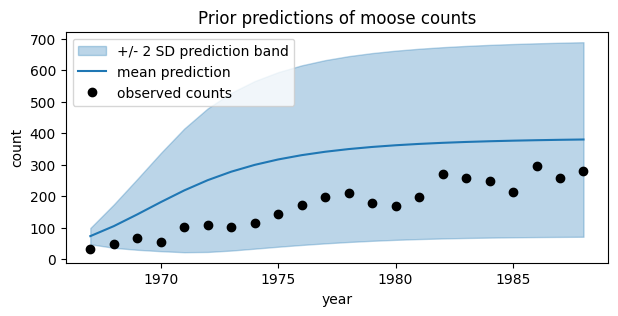

In [16]:
# plot the prior predictive mean and +/- 2 standard deviation interval
plot_predictive_interval(prior_mean_counts, prior_sd_counts, observed_counts, 
                         title='Prior predictions of moose counts')

# 3. Is the posterior distribution reasonable?

We now produce the same exact plot using the posterior instead of the prior, providing a summary
of the *posterior predictive* distribution.

The great thing here is that none of the above code needs to change. We simply pass in the 
posterior over the arguments to `ricker()` instead of the prior.

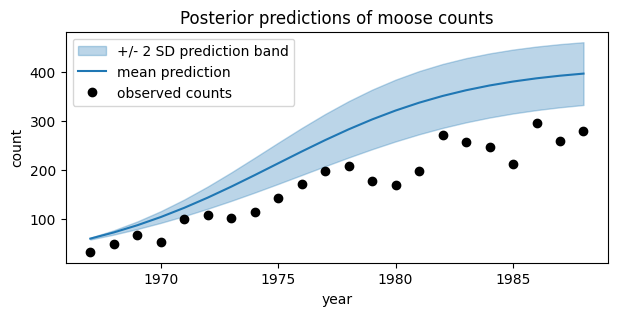

In [17]:
posterior_predicted_counts = ricker(r=posterior['r'], K=posterior['K'], n0=50, years=n_years)
posterior_mean_counts = mean(posterior_predicted_counts)
posterior_sd_counts = standard_deviation(posterior_predicted_counts)

plot_predictive_interval(posterior_mean_counts, posterior_sd_counts, observed_counts, 
                         title='Posterior predictions of moose counts')

Note that the reason the predictions lie above the data is that we are plotting the predictions of the 
latent moose population, which is larger than the observed population due to under-counting.

One thing to note in the above cell is that `ricker(r=posterior['r'], K=posterior['K'], ...)` retains the 
joint dependence structure between the $r$ and $K$ marginals of the joint distribution `posterior`. ProbPipe
is smart enough to know that the arguments come from the same parent distribution. 

## 4. Formal model checking

The above visual checks are useful starting points, but it is often advisable to run more formal quantitative
checks to ensure model predictions for certain quantities of interest are reasonable. These are typically computed by:
1. choosing a particular statistic of interest
2. compute the statistic for the observed data
3. simulate replicate data from the model and compute the statistic for each replicate
4. compare the observed statistic to the simulated statistics 

The result of the check is often quantified with a *p-value*: the fraction of replicates whose statistic is at 
least as large as the observed statistic. A p-value near 0 or 1 means the model rarely produces data that look like 
the observed data (with respect to the particular statistic). 

ProbPipe makes computing predictive checks easy with `predictive_check`. We run this below for one particular 
statistic: a summary of how much the population jumps from year to year. More precisely, the standard
deviation of the year-to-year changes. Once again, testing the prior versus the posterior requires nothing more
than changing the argument to `predictive_check`. 

In [18]:
# the statistic to test
def change_spread(y: jax.Array) -> jax.Array:
    return jnp.std(jnp.diff(y))

prior_check = predictive_check(likelihood, prior, change_spread, observed_counts)
posterior_check = predictive_check(likelihood, posterior, change_spread, observed_counts)

prior check p-value: 0.06
posterior check p-value: 0.002


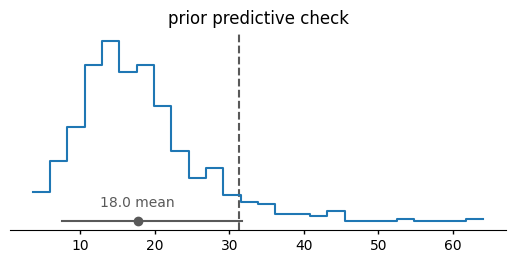

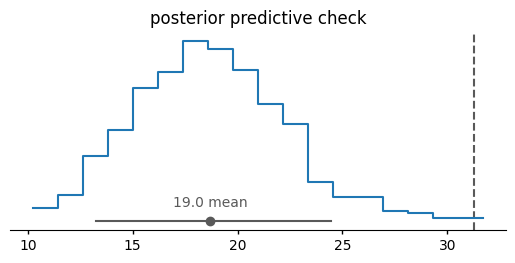

In [19]:
# inspect the results of the tests
print('prior check p-value:', prior_check['p_value'])
print('posterior check p-value:', posterior_check['p_value'])
plot_model_check(prior_check, 'prior predictive check')
plot_model_check(posterior_check, 'posterior predictive check')

The results of these tests indicate that there is some cause for concern. The observed data tends to jump
around from year to year a lot more than the model predicts. The posterior predictive test is the more 
concerning one here, since the simulated statistic exceeds the observed one only 0.2% of the time.

# 5. Provenance tracking

Let's conclude this tutorial as we did the previous one, by summarizing the steps used to produce
a ProbPipe object. The below code does this for the objects returned by the prior and posterior
predictive checks.  

In [21]:
print(prior_check.provenance)

1. LogNormal & LogNormal & Beta
2. prior = with_label(1)
3. predictive_check(likelihood, 2, test_fns, observed_data, num_replications)  route body, exact


In [20]:
print(posterior_check.provenance)

1. LogNormal & LogNormal & Beta
2. prior = with_label(1)
3. likelihood & 2
4. model = with_label(3)
5. model = condition_on(4, given)                    route inference_methods, method blackjax_nuts, approximate
6. posterior = with_label(5)
7. predictive_check(likelihood, 6, test_fns, observed_data, num_replications)  route body, exact


## Summary

This tutorial highlighted one of ProbPipe's core principles: to treat distributions as first-class objects.
ProbPipe allows wrapping an ordinary Python function so that it correctly propagates randomness when one 
or more of its arguments are distributions.

In particular, this tutorial illustrated:
1. how to propagate uncertainty through functions by passing distributions as arguments
2. how to run prior and posterior predictive checks
3. two new operations that can be run on distributions: `mean` and `standard_deviation`

[Tutorial 3](03_modifying_model.ipynb) continues introducing ProbPipe using the same moose count example.